# What the regime classifier relies on: permutation importance of the boosted tree

Notebook 06's chosen classifier (gradient-boosted trees, `HistGradientBoostingClassifier`, balanced class weights, 300
iterations) reads 42 inputs per window: the TCN-VAE encoder's 32 posterior means, the LSTM-VAE detector's three novelty
scores and the seven rhythm features. Notebook 06 showed the combination beats any single source (macro F1 0.868 against
0.66 to 0.69 for a linear read-out of the latent alone) but not which inputs the tree actually uses.

| | |
|---|---|
| model | notebook 06's exactly: fitted on all four validation participants, one per seed (each seed's own encoder and detector runs) |
| metric | notebook 06's decision: probabilities, 0.5 s causal median by recording, most probable regime; macro F1 and each regime's recall on the four test participants |
| importance | shuffle one group of columns across the test windows (one shared permutation per group, so its internal correlations survive) and measure the drop; groups `REPEATS_GROUP` times, single features `REPEATS_FEATURE` times, per seed; mean over repeats, then mean ± SD over the three seeds |
| reading | a drop is what the tree cannot recover from the other inputs. Inputs that share information (the novelty scores are computed from a latent, the latent sees the rhythm features as input channels) can stand in for each other, so single-feature drops understate shared information; the group drops are the headline |

Results `results/12_*.csv`, figure `figures/12_classifier_importance.png`.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import _regime_classifier as rc

ROOT = REPO / 'notebooks' / 'nature' / 'model_exploration'
DATA = REPO / 'data' / 'processed_nature' / 'ae'
CACHE = REPO / 'data' / 'cache' / 'nature' / 'novelty'
FIG_DIR, RESULTS = Path.cwd() / 'figures', Path.cwd() / 'results'
SEEDS = (0, 1, 2)
ENCODER = ROOT / 'runs_train_class' / 'id_ood_safe' / 'vae' / 'tcn_vae_raw_3s_spectral_b128_fixed_s{seed}'   # notebook 06's
DETECTOR = ROOT / 'runs' / 'vae' / 'lstm_vae_raw_3s_b1_fixed_s{seed}'
NOVELTY = ['LOF, raw latent', 'Mahalanobis, latent', 'posterior variance']
REPEATS_GROUP, REPEATS_FEATURE = 10, 5
RHYTHM_NAMES = {'dominant_hz_l': 'dominant frequency, left', 'dominant_hz_r': 'dominant frequency, right',
                'spectral_entropy_l': 'spectral entropy, left', 'spectral_entropy_r': 'spectral entropy, right',
                'stride_regularity_l': 'stride regularity, left', 'stride_regularity_r': 'stride regularity, right',
                'step_regularity': 'step regularity'}
NAMES = ([f'latent f{u // 8} · t{u % 8}' for u in range(32)] + ['LOF', 'Mahalanobis', 'posterior variance']
         + [RHYTHM_NAMES[c] for c in rc.RHYTHM])                     # the 42 columns, in notebook 06's order
GROUP_OF = ['TCN-VAE latent'] * 32 + ['LSTM-VAE novelty'] * 3 + ['rhythm features'] * 7
GROUPS = {g: [i for i, h in enumerate(GROUP_OF) if h == g] for g in dict.fromkeys(GROUP_OF)}
GROUP_C = {'TCN-VAE latent': '#1baf7a', 'LSTM-VAE novelty': '#4a3aa7', 'rhythm features': '#eda100'}   # never a regime colour

meta = json.loads((DATA / 'meta.json').read_text())
tables = {k: pd.read_parquet(DATA / meta['inputs'][k]['table']) for k in ('raw_3s', 'raw_3s_spectral')}
rows = {s: rc.get_split_rows(tables['raw_3s'], s) for s in ('val', 'test')}
keys = {s: r[['rec', 'end']] for s, r in rows.items()}
y = {s: r['controller_class'].astype(str).to_numpy() for s, r in rows.items()}
print({s: f'{len(v):,} windows' for s, v in y.items()}, {g: len(c) for g, c in GROUPS.items()})

{'val': '173,590 windows', 'test': '137,955 windows'} {'TCN-VAE latent': 32, 'LSTM-VAE novelty': 3, 'rhythm features': 7}


## 1. Refit notebook 06's classifier per seed and check it reproduces

In [2]:
t0 = time.time()
x, models, base = {}, {}, []
for seed in SEEDS:
    lat = rc.get_latents(Path(str(ENCODER).format(seed = seed)), tables['raw_3s_spectral'], keys)
    nov = rc.get_novelty(Path(str(DETECTOR).format(seed = seed)), tables['raw_3s'], keys, NOVELTY, CACHE)
    x[seed] = {s: np.concatenate([lat[s], nov[s], rows[s][rc.RHYTHM].to_numpy(dtype = np.float64)], axis = 1) for s in ('val', 'test')}
    models[seed] = HistGradientBoostingClassifier(class_weight = 'balanced', max_iter = 300, random_state = seed).fit(x[seed]['val'], y['val'])
    base.append({'seed': seed, **rc.get_regime_metrics(y['test'], rc.get_predicted_regimes(models[seed], x[seed]['test'], rows['test']))})
base = pd.DataFrame(base).set_index('seed')
ref = pd.read_csv(RESULTS / '06_regime_scores.csv')
ref = ref[(ref['model'] == 'boosted trees') & (ref['features'] == 'latent + novelty + rhythm')].set_index('seed')['test macro F1']
np.testing.assert_allclose(base['macro F1'].to_numpy(), ref.loc[list(SEEDS)].to_numpy(), atol = 1e-9)   # identical to notebook 06
display(base.round(3))
print(f'reproduces notebook 06 exactly; {time.time() - t0:.0f} s')

,macro F1,"recall, ID-safe","recall, OOD-safe","recall, OOD-dangerous",dangerous sent to the spline (%),safe switched off (%)
seed,,,,,,
0,0.864,0.933,0.908,0.799,0.0,2.906
1,0.867,0.934,0.917,0.784,0.0,2.847
2,0.874,0.919,0.926,0.799,0.0,2.640


reproduces notebook 06 exactly; 63 s


## 2. Permutation importance: groups, then single features

In [3]:
GROUP_CSV, FEATURE_CSV = RESULTS / '12_importance_groups.csv', RESULTS / '12_importance_features.csv'
if GROUP_CSV.exists() and FEATURE_CSV.exists():                    # about 25 min to recompute: delete both files to rerun
    group_imp, feature_imp = pd.read_csv(GROUP_CSV), pd.read_csv(FEATURE_CSV)
    print(f'read {GROUP_CSV.name}, {FEATURE_CSV.name}')
else:
    t0 = time.time()
    parts_g, parts_f = [], []
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        args = (models[seed], x[seed]['test'], y['test'], rows['test'])
        parts_g.append(rc.get_permutation_importance(*args, GROUPS, REPEATS_GROUP, rng).assign(seed = seed))
        parts_f.append(rc.get_permutation_importance(*args, {n: [i] for i, n in enumerate(NAMES)}, REPEATS_FEATURE, rng).assign(seed = seed))
        print(f'seed {seed} done, {time.time() - t0:.0f} s')
    group_imp = pd.concat(parts_g, ignore_index = True)
    feature_imp = pd.concat(parts_f, ignore_index = True).rename(columns = {'group': 'feature'})
    feature_imp['group'] = feature_imp['feature'].map(dict(zip(NAMES, GROUP_OF)))
    group_imp.to_csv(GROUP_CSV, index = False)
    feature_imp.to_csv(FEATURE_CSV, index = False)

read 12_importance_groups.csv, 12_importance_features.csv


In [4]:
def get_summary(frame: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    # mean over repeats within each seed, then mean and SD over seeds
    per_seed = frame.drop(columns = 'repeat').groupby([*by, 'seed']).mean(numeric_only = True)
    return per_seed.groupby(by).agg(['mean', 'std'])


def show(summary: pd.DataFrame) -> pd.DataFrame:
    # 'mean ± sd' strings for display
    cols = dict.fromkeys(c for c, _ in summary.columns)
    return pd.DataFrame({c: summary[(c, 'mean')].map('{:.3f}'.format) + ' ± ' + summary[(c, 'std')].map('{:.3f}'.format) for c in cols})


groups_s = get_summary(group_imp, ['group']).sort_values(('drop, macro F1', 'mean'), ascending = False)
features_s = get_summary(feature_imp, ['feature', 'group']).sort_values(('drop, macro F1', 'mean'), ascending = False)
print('baseline (test, mean over seeds):', base.mean().round(3).to_dict())
display(show(groups_s))
display(show(features_s.head(12)))

baseline (test, mean over seeds): {'macro F1': 0.868, 'recall, ID-safe': 0.929, 'recall, OOD-safe': 0.917, 'recall, OOD-dangerous': 0.794, 'dangerous sent to the spline (%)': 0.0, 'safe switched off (%)': 2.798}


,"drop, macro F1","drop, recall, ID-safe","drop, recall, OOD-safe","drop, recall, OOD-dangerous","rise, dangerous sent to the spline (%)","rise, safe switched off (%)"
group,,,,,,
LSTM-VAE novelty,0.287 ± 0.004,0.855 ± 0.020,-0.043 ± 0.012,0.095 ± 0.036,2.889 ± 0.453,-0.930 ± 0.543
TCN-VAE latent,0.287 ± 0.010,0.030 ± 0.019,-0.018 ± 0.021,0.781 ± 0.008,0.000 ± 0.000,-2.601 ± 0.156
rhythm features,0.065 ± 0.009,0.022 ± 0.015,0.008 ± 0.008,0.236 ± 0.039,0.009 ± 0.015,-1.774 ± 0.253


,,"drop, macro F1","drop, recall, ID-safe","drop, recall, OOD-safe","drop, recall, OOD-dangerous","rise, dangerous sent to the spline (%)","rise, safe switched off (%)"
feature,group,,,,,,
posterior variance,LSTM-VAE novelty,0.149 ± 0.035,0.592 ± 0.074,-0.028 ± 0.009,-0.026 ± 0.014,0.017 ± 0.016,0.557 ± 0.319
Mahalanobis,LSTM-VAE novelty,0.093 ± 0.009,0.402 ± 0.037,-0.054 ± 0.009,0.126 ± 0.055,0.310 ± 0.114,-1.291 ± 0.493
latent f1 · t0,TCN-VAE latent,0.040 ± 0.030,0.001 ± 0.001,-0.018 ± 0.015,0.216 ± 0.158,0.001 ± 0.002,-1.371 ± 1.119
LOF,LSTM-VAE novelty,0.013 ± 0.023,0.154 ± 0.110,-0.034 ± 0.010,0.009 ± 0.006,0.009 ± 0.015,-0.224 ± 0.060
"spectral entropy, right",rhythm features,0.009 ± 0.005,-0.008 ± 0.003,0.007 ± 0.005,0.029 ± 0.012,0.003 ± 0.005,-0.411 ± 0.199
latent f2 · t0,TCN-VAE latent,0.007 ± 0.010,-0.001 ± 0.003,-0.008 ± 0.014,0.059 ± 0.081,0.000 ± 0.000,-0.758 ± 0.772
"dominant frequency, right",rhythm features,0.006 ± 0.005,0.008 ± 0.010,0.006 ± 0.012,0.001 ± 0.009,0.000 ± 0.000,-0.013 ± 0.265
"spectral entropy, left",rhythm features,0.006 ± 0.003,-0.003 ± 0.003,0.001 ± 0.004,0.028 ± 0.003,0.008 ± 0.013,-0.357 ± 0.077
latent f3 · t7,TCN-VAE latent,0.004 ± 0.004,0.001 ± 0.001,-0.005 ± 0.006,0.036 ± 0.039,0.000 ± 0.000,-0.408 ± 0.504


## 3. Slide figure

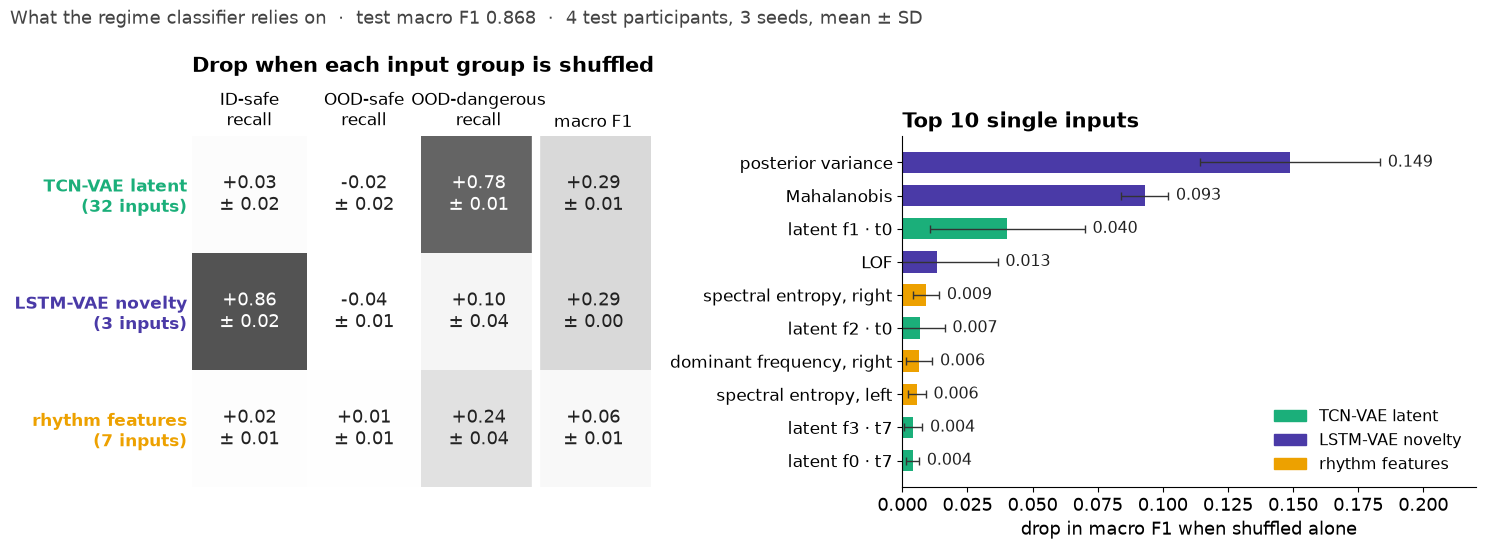

In [5]:
TOP = 10
plt.rcParams.update({'font.size': 13, 'axes.spines.top': False, 'axes.spines.right': False})
fig, (ax_g, ax_f) = plt.subplots(1, 2, figsize = (15, 5.6), gridspec_kw = {'width_ratios': [1, 1.25]})

# left: which regime each group serves, as the drop in that regime's recall (plus macro F1) when the group is shuffled
order = list(GROUPS)
cols = ['recall, ID-safe', 'recall, OOD-safe', 'recall, OOD-dangerous', 'macro F1']
heads = ['ID-safe\nrecall', 'OOD-safe\nrecall', 'OOD-dangerous\nrecall', 'macro F1']
grid = np.array([[groups_s.loc[g, (f'drop, {c}', 'mean')] for c in cols] for g in order])          # (3 groups, 4)
sd = np.array([[groups_s.loc[g, (f'drop, {c}', 'std')] for c in cols] for g in order])
ax_g.imshow(np.clip(grid, 0, 1), cmap = 'Greys', vmin = 0, vmax = 1.15, aspect = 'auto')
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ink = 'white' if grid[i, j] > .55 else '#222'
        ax_g.text(j, i, f'{grid[i, j]:+.2f}\n± {sd[i, j]:.2f}', ha = 'center', va = 'center', fontsize = 13, color = ink)
ax_g.axvline(2.5, color = 'white', lw = 6)                                       # separate the per-regime columns from macro F1
ax_g.set_xticks(range(len(cols)), heads, fontsize = 12)
ax_g.xaxis.tick_top()
ax_g.set_yticks(range(len(order)), [f'{g}\n({len(GROUPS[g])} inputs)' for g in order], fontsize = 12)
for tick, g in zip(ax_g.get_yticklabels(), order):
    tick.set_color(GROUP_C[g]); tick.set_fontweight('bold')
ax_g.tick_params(length = 0)
ax_g.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
ax_g.set_title('Drop when each input group is shuffled', loc = 'left', fontsize = 15, fontweight = 'bold', pad = 46)

# right: the single inputs that matter most
f = features_s.head(TOP)
fv, fsd = f[('drop, macro F1', 'mean')].to_numpy(), f[('drop, macro F1', 'std')].to_numpy()
names, groups_f = [i[0] for i in f.index], [i[1] for i in f.index]
pos = np.arange(TOP)[::-1]
ax_f.barh(pos, fv, xerr = fsd, color = [GROUP_C[gr] for gr in groups_f], height = .65, error_kw = dict(ecolor = '#333', capsize = 3, lw = 1))
for p, v, s in zip(pos, fv, fsd):
    ax_f.text(v + s + .003, p, f'{v:.3f}', va = 'center', fontsize = 11.5, color = '#222')
ax_f.set_yticks(pos, names, fontsize = 12)
ax_f.set_xlabel('drop in macro F1 when shuffled alone')
ax_f.set_title(f'Top {TOP} single inputs', loc = 'left', fontsize = 15, fontweight = 'bold')
ax_f.set_xlim(0, (fv + fsd).max() * 1.2)
handles = [plt.Rectangle((0, 0), 1, 1, color = c) for c in GROUP_C.values()]
ax_f.legend(handles, list(GROUP_C), loc = 'lower right', frameon = False, fontsize = 11.5)
fig.suptitle(f"What the regime classifier relies on  ·  test macro F1 {base['macro F1'].mean():.3f}  ·  4 test participants, 3 seeds, mean ± SD",
             fontsize = 13, x = .01, ha = 'left', color = '#444')
fig.tight_layout()
fig.savefig(FIG_DIR / '12_classifier_importance.png', dpi = 200, bbox_inches = 'tight')
plt.show()

Which regime each group serves: the drop in each regime's recall when the group is shuffled.

In [6]:
cols = [f'drop, recall, {r}' for r in rc.REGIMES] + ['rise, dangerous sent to the spline (%)', 'rise, safe switched off (%)']
display(show(groups_s[[(c, s) for c in cols for s in ('mean', 'std')]]))

,"drop, recall, ID-safe","drop, recall, OOD-safe","drop, recall, OOD-dangerous","rise, dangerous sent to the spline (%)","rise, safe switched off (%)"
group,,,,,
LSTM-VAE novelty,0.855 ± 0.020,-0.043 ± 0.012,0.095 ± 0.036,2.889 ± 0.453,-0.930 ± 0.543
TCN-VAE latent,0.030 ± 0.019,-0.018 ± 0.021,0.781 ± 0.008,0.000 ± 0.000,-2.601 ± 0.156
rhythm features,0.022 ± 0.015,0.008 ± 0.008,0.236 ± 0.039,0.009 ± 0.015,-1.774 ± 0.253


## Findings

Baseline (test, mean over seeds, reproduces notebook 06 exactly): macro F1 0.868; recall ID-safe 0.93, OOD-safe 0.92,
OOD-dangerous 0.79; no dangerous window sent to the spline; 2.8% of safe windows switched off.

- **The two encoders split the job, as the pipeline intends.** Shuffling the **LSTM-VAE novelty scores** drops ID-safe
  recall by 0.86 ± 0.02 and sends 2.9% of dangerous windows to the spline: they are how the tree recognises familiar
  movement. Shuffling the **TCN-VAE latent** drops dangerous recall by 0.78 ± 0.01 and leaves ID-safe almost untouched
  (0.03): it is how the tree recognises dangerous movement. Each group alone costs the same 0.29 in macro F1, for
  different regimes.
- **The rhythm features add a smaller, dangerous-side contribution:** dangerous recall drops 0.24 ± 0.04 without them
  (macro F1 0.06), though the latent already sees them as input channels.
- **OOD-safe is the fallback.** Shuffling any group raises OOD-safe recall slightly (by up to 0.04) and lowers safe
  switch-offs: when the tree loses information it defaults to the estimator. This is the same behaviour as a dangerous
  task it never saw (notebook 06, section 6).
- **Single inputs:** posterior variance (0.149 ± 0.035) and Mahalanobis distance (0.093 ± 0.009) are the two most important
  single inputs; **LOF adds little on its own (0.013 ± 0.023, within noise)**, presumably because the other two carry the
  same information. LOF is also the costliest score to run on the device (a 20-nearest-neighbour search against stored
  training latents), so a classifier without it is worth testing before deployment. In the latent, one unit (filter 1,
  first time step) stands out (0.040); the rest share their information, so singly they barely register while together
  they matter most.
- **Limits:** permutation importance measures what the tree cannot recover from its other inputs on these four test
  participants; it understates information that inputs share, and shuffled rows can be combinations no real window has.
  Whether LOF can be dropped needs a refit without it, not this table.